# Структура сырого датасета Amazon Reviews 2023 — Toys & Games

Готовый ATG (`data/ATG`) предобработан не нами: неизвестно, какие фильтры применялись, как
строились последовательности и как товары пронумерованы. Перед собственной предобработкой
разбираемся, что лежит в сырых файлах `data/Toys`:

* `Toys_and_Games.jsonl` — отзывы (взаимодействия пользователь → товар), JSON на строку;
* `meta_Toys_and_Games.jsonl` — метаданные товаров, JSON на строку.

План:

1. Файлы и первые записи.
2. Схема: какие поля, каких типов, как часто пусты (по началу файла).
3. Кэш: один потоковый проход по каждому файлу → компактный parquet без картинок, видео и
   текстов отзывов. Дальше ноутбук работает только с кэшем.
4. Отзывы: идентификаторы (`asin` против `parent_asin`), дубликаты, время и одинаковые
   timestamp, рейтинги, активность пользователей и товаров, k-core.
5. Метаданные: заполненность текстовых полей, длины, категории, `details`, покрытие товаров
   из отзывов; текстовые описания товаров предобработанного датасета (5.5).
6. Сверка с готовым ATG: что о его предобработке можно понять по самим сплитам.

Первый прогон читает ~10 ГБ JSON и занимает порядка 10–15 минут; повторные — секунды.

In [29]:
import json
import os
import re
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)

RAW_DIR      = Path('../data/Toys')
REVIEWS_PATH = RAW_DIR / 'Toys_and_Games.jsonl'
META_PATH    = RAW_DIR / 'meta_Toys_and_Games.jsonl'
ATG_DIR      = Path('../data/ATG')
CACHE_DIR    = Path(os.environ.get('TOYS_CACHE_DIR', '../data/processed/toys_raw'))

LIMIT         = int(os.environ['TOYS_LIMIT']) if 'TOYS_LIMIT' in os.environ else None   # строк на файл; None — весь файл
CHUNK         = int(os.environ.get('TOYS_CHUNK', 1_000_000))   # строк в одной row group parquet
SCHEMA_SAMPLE = 200_000        # строк с начала файла для разбора схемы
SEED          = 42

# Статистика ATG из AlphaFuse (Table 1) — ориентир для сверки в разделе 6
ATG_PAPER = {'users': 19_412, 'items': 11_924, 'interactions': 138_444}

CACHE_DIR.mkdir(parents=True, exist_ok=True)

## 1. Файлы и первые записи

In [30]:
for p in (REVIEWS_PATH, META_PATH):
    print(f'{p.name:32s} {p.stat().st_size / 2**30:6.2f} GiB')


def short(v, n=150):
    """Сокращённое представление значения для печати."""
    if isinstance(v, list):
        head = [short(x, 60) for x in v[:3]]
        return f'list[{len(v)}] {head}' + (' ...' if len(v) > 3 else '')
    if isinstance(v, dict):
        return f'dict[{len(v)}] ' + short(json.dumps(v, ensure_ascii=False), n)
    s = repr(v)
    return s if len(s) <= n else s[:n] + '...'


def first_records(path, n):
    with open(path, 'rb') as f:
        return [json.loads(next(f)) for _ in range(n)]


for path in (REVIEWS_PATH, META_PATH):
    print(f'\n===== {path.name}: первая запись =====')
    for k, v in first_records(path, 1)[0].items():
        print(f'  {k:18s} {short(v)}')

Toys_and_Games.jsonl               6.81 GiB
meta_Toys_and_Games.jsonl          2.46 GiB

===== Toys_and_Games.jsonl: первая запись =====
  rating             5.0
  title              'Granddaughters love them!'
  text               'I purchased several of these for my granddaughters for Xmas & they absolutely love them. In fact so do their brothers. Lol. Be aware that there are t...
  images             list[0] []
  asin               'B09QH7QJS7'
  parent_asin        'B09QH7QJS7'
  user_id            'AFKZENTNBQ7A7V7UXW5JJI6UGRYQ'
  timestamp          1677939664713
  helpful_vote       0
  verified_purchase  True

===== meta_Toys_and_Games.jsonl: первая запись =====
  main_category      'Toys & Games'
  title              'KUNGOON Happy Anniversary Balloon Banner,Wedding Anniversary Party Decorations,Love Party and Anniversary Party Supplies,16 Inch Gold Aluminum Foil.'
  average_rating     4.5
  rating_number      241
  features           list[0] []
  description        list[0] []
  

## 2. Схема полей

По первым `SCHEMA_SAMPLE` строкам каждого файла считаем для каждого поля: долю записей, где
оно есть; долю пустых значений (`None`, `''`, `[]`, `{}`); встреченные типы (у списков — тип
первого элемента); у словарей и списков словарей — ключи вложенных объектов.

Начало файла может быть нерепрезентативным (если файл упорядочен, например, по товару). Точные
частоты ключей по всему файлу посчитает проход в разделе 3.

In [31]:
def is_empty(v):
    return v is None or v == '' or v == [] or v == {}


def survey(path, n):
    present, empty = Counter(), Counter()
    types, nested  = defaultdict(Counter), defaultdict(Counter)
    examples = {}
    n_read = 0
    with open(path, 'rb') as f:
        for line in f:
            if n_read >= n:
                break
            n_read += 1
            for k, v in json.loads(line).items():
                present[k] += 1
                t = type(v).__name__
                if isinstance(v, list) and v:
                    t += f'[{type(v[0]).__name__}]'
                types[k][t] += 1
                if is_empty(v):
                    empty[k] += 1
                elif k not in examples:
                    examples[k] = v
                if isinstance(v, dict):
                    nested[k].update(v.keys())
                elif isinstance(v, list):
                    for x in v:
                        if isinstance(x, dict):
                            nested[k].update(x.keys())
    table = pd.DataFrame([{
        'field':     k,
        'present_%': 100 * present[k] / n_read,
        'empty_%':   100 * empty[k] / present[k],
        'types':     ', '.join(f'{t}:{c}' for t, c in types[k].most_common()),
        'example':   short(examples.get(k), 90),
    } for k in present]).set_index('field')
    return table, nested, n_read


schema_rev, nested_rev, n = survey(REVIEWS_PATH, SCHEMA_SAMPLE)
print(f'Отзывы: {n:,} строк')
schema_rev.round(2)

Отзывы: 200,000 строк


,present_%,empty_%,types,example
field,,,,
rating,100.0,0.00,float:200000,5.0
title,100.0,0.00,str:200000,'Granddaughters love them!'
text,100.0,0.00,str:200000,'I purchased several of these for my granddaughters for Xmas & they absolutely love them. ...
images,100.0,93.15,"list:186309, list[dict]:13691","list[5] ['dict[4] \'{""small_image_url"": ""https://m.media-amazon.com/images/I/61...', 'dict[4] \'{""small_image_url"": ..."
asin,100.0,0.00,str:200000,'B09QH7QJS7'
parent_asin,100.0,0.00,str:200000,'B09QH7QJS7'
user_id,100.0,0.00,str:200000,'AFKZENTNBQ7A7V7UXW5JJI6UGRYQ'
timestamp,100.0,0.00,int:200000,1677939664713
helpful_vote,100.0,0.00,int:200000,0


In [32]:
schema_meta, nested_meta, n = survey(META_PATH, SCHEMA_SAMPLE)
print(f'Метаданные: {n:,} строк')
schema_meta.round(2)

Метаданные: 200,000 строк


,present_%,empty_%,types,example
field,,,,
main_category,100.0,0.94,"str:198113, NoneType:1887",'Toys & Games'
title,100.0,0.02,str:200000,"'KUNGOON Happy Anniversary Balloon Banner,Wedding Anniversary Party Decorations,Love Party..."
average_rating,100.0,0.00,float:200000,4.5
rating_number,100.0,0.00,int:200000,241
features,100.0,17.33,"list[str]:165343, list:34657","list[5] [""'🦋 Mothman’s bright red eyes could stare you down in an inst..."", ""'🦋 This Mothman plushie is looking for ..."
description,100.0,33.27,"list[str]:133455, list:66545","list[1] [""'🦋 Description: Mothman’s bright red eyes could stare you do...""]"
price,100.0,44.65,"float:110691, NoneType:89309",18.99
images,100.0,0.00,"list[dict]:199994, list:6","list[3] ['dict[4] \'{""thumb"": ""https://m.media-amazon.com/images/I/41enwmDCoZL....', 'dict[4] \'{""thumb"": ""https://m..."
videos,100.0,47.84,"list[dict]:104310, list:95690","list[8] ['dict[3] \'{""title"": ""Pretty Cool!"", ""url"": ""https://www.amazon.com/vd...', 'dict[3] \'{""title"": ""Product a..."


In [33]:
# Ключи вложенных объектов: сколько раз встретился каждый (top-25)
for name, nested in (('reviews', nested_rev), ('meta', nested_meta)):
    for field, keys in nested.items():
        print(f'{name}.{field}: {len(keys)} разных ключей')
        print('   ', ', '.join(f'{k} ({c:,})' for k, c in keys.most_common(25)))

reviews.images: 4 разных ключей
    small_image_url (32,070), medium_image_url (32,070), large_image_url (32,070), attachment_type (32,070)
meta.images: 4 разных ключей
    large (926,197), variant (926,197), thumb (926,194), hi_res (926,194)
meta.videos: 3 разных ключей
    title (586,316), url (586,316), user_id (586,316)
meta.details: 1548 разных ключей
    Manufacturer (180,714), Item Weight (175,321), Best Sellers Rank (132,336), Manufacturer recommended age (129,300), Product Dimensions (120,836), Item model number (102,816), Is Discontinued By Manufacturer (89,534), Brand (86,181), Package Dimensions (54,428), Material (48,254), Date First Available (39,486), Theme (38,829), Color (36,974), Release date (32,474), Age Range (Description) (26,420), Item Dimensions LxWxH (25,066), Country of Origin (24,685), Number of Pieces (23,449), Department (19,756), Occasion (14,495), Unit Count (13,931), Size (12,638), Style (11,878), Shape (11,631), Number of Items (11,283)
meta.author: 3 р

## 3. Кэш в parquet

Один проход по каждому файлу. Из отзывов остаются идентификаторы, время, рейтинг и служебные
признаки; сам текст отзыва не нужен для рекомендера, от него — только длины. Из метаданных
остаются все текстовые поля товара; картинки и видео сводятся к числу штук, `details` и
`bought_together` хранятся JSON-строкой, незнакомые ключи — в `extra`.

Рядом с parquet пишется `<имя>_info.json`: число строк, битых строк и частоты ключей по всему
файлу, а также `LIMIT`, с которым строился кэш (при другом `LIMIT` кэш пересобирается).

In [34]:
REVIEW_SCHEMA = pa.schema([
    ('user_id', pa.string()), ('asin', pa.string()), ('parent_asin', pa.string()),
    ('timestamp', pa.int64()), ('rating', pa.float32()), ('helpful_vote', pa.int32()),
    ('verified_purchase', pa.bool_()), ('n_images', pa.int16()),
    ('title_len', pa.int32()), ('text_len', pa.int32()),
])


def review_row(r):
    return (r.get('user_id'), r.get('asin'), r.get('parent_asin'), r.get('timestamp'),
            r.get('rating'), r.get('helpful_vote'), r.get('verified_purchase'),
            len(r.get('images') or []), len(r.get('title') or ''), len(r.get('text') or ''))


META_KNOWN = {'parent_asin', 'main_category', 'title', 'average_rating', 'rating_number', 'price',
              'store', 'features', 'description', 'categories', 'details', 'bought_together',
              'images', 'videos'}

META_SCHEMA = pa.schema([
    ('parent_asin', pa.string()), ('main_category', pa.string()), ('title', pa.string()),
    ('average_rating', pa.float32()), ('rating_number', pa.int64()),
    ('price', pa.float64()), ('price_raw', pa.string()), ('store', pa.string()),
    ('features', pa.list_(pa.string())), ('description', pa.list_(pa.string())),
    ('categories', pa.list_(pa.string())), ('details', pa.string()),
    ('bought_together', pa.string()), ('n_images', pa.int16()), ('n_videos', pa.int16()),
    ('extra', pa.string()),
])


def _str_list(v):
    return [str(x) for x in v] if isinstance(v, list) else ([] if v is None else [str(v)])


def _json_or_none(v):
    return None if v is None else json.dumps(v, ensure_ascii=False)


def meta_row(r):
    price = r.get('price')
    extra = {k: v for k, v in r.items() if k not in META_KNOWN}
    return (r.get('parent_asin'), r.get('main_category'), r.get('title'),
            r.get('average_rating'), r.get('rating_number'),
            price if isinstance(price, (int, float)) and not isinstance(price, bool) else None,
            _json_or_none(price), r.get('store'),
            _str_list(r.get('features')), _str_list(r.get('description')),
            _str_list(r.get('categories')), _json_or_none(r.get('details')),
            _json_or_none(r.get('bought_together')),
            len(r.get('images') or []), len(r.get('videos') or []),
            _json_or_none(extra) if extra else None)


def build_cache(src, name, schema, to_row):
    """Потоково src (JSONL) → CACHE_DIR/<name>.parquet + <name>_info.json. Возвращает info."""
    dst, info_path = CACHE_DIR / f'{name}.parquet', CACHE_DIR / f'{name}_info.json'
    if dst.exists() and info_path.exists():
        info = json.loads(info_path.read_text())
        if info['limit'] == LIMIT:
            print(f'{name}: кэш есть ({dst})')
            return info

    tmp = dst.with_suffix('.tmp')
    keys, n_lines, n_bad = Counter(), 0, 0
    cols = [[] for _ in schema]

    def flush(writer):
        if cols[0]:
            writer.write_table(pa.table([pa.array(c, type=f.type) for c, f in zip(cols, schema)],
                                        schema=schema))
            for c in cols:
                c.clear()

    total = src.stat().st_size if LIMIT is None else None
    with open(src, 'rb') as f, pq.ParquetWriter(tmp, schema) as writer, \
            tqdm(total=total, unit='B', unit_scale=True, desc=name) as bar:
        pending = 0
        for line in f:
            if LIMIT is not None and n_lines >= LIMIT:
                break
            n_lines += 1
            pending += len(line)
            try:
                rec = json.loads(line)
            except json.JSONDecodeError:
                n_bad += 1
                continue
            keys.update(rec.keys())
            for c, v in zip(cols, to_row(rec)):
                c.append(v)
            if len(cols[0]) >= CHUNK:
                flush(writer)
            if n_lines % 200_000 == 0:
                bar.update(pending)
                pending = 0
        flush(writer)
        bar.update(pending)

    tmp.replace(dst)
    info = {'limit': LIMIT, 'lines': n_lines, 'bad_lines': n_bad, 'keys': dict(keys.most_common())}
    info_path.write_text(json.dumps(info, indent=1))
    return info


rev_info  = build_cache(REVIEWS_PATH, 'reviews', REVIEW_SCHEMA, review_row)
meta_info = build_cache(META_PATH, 'meta', META_SCHEMA, meta_row)

for name, info in (('reviews', rev_info), ('meta', meta_info)):
    print(f'\n{name}: строк {info["lines"]:,}, битых {info["bad_lines"]:,}')
    print('  доля записей с ключом:',
          ', '.join(f'{k} {100 * c / info["lines"]:.1f}%' for k, c in info['keys'].items()))

reviews: кэш есть (..\data\processed\toys_raw\reviews.parquet)
meta: кэш есть (..\data\processed\toys_raw\meta.parquet)

reviews: строк 16,260,406, битых 0
  доля записей с ключом: rating 100.0%, title 100.0%, text 100.0%, images 100.0%, asin 100.0%, parent_asin 100.0%, user_id 100.0%, timestamp 100.0%, helpful_vote 100.0%, verified_purchase 100.0%

meta: строк 890,874, битых 0
  доля записей с ключом: main_category 100.0%, title 100.0%, average_rating 100.0%, rating_number 100.0%, features 100.0%, description 100.0%, price 100.0%, images 100.0%, videos 100.0%, store 100.0%, categories 100.0%, details 100.0%, parent_asin 100.0%, bought_together 100.0%, subtitle 0.0%, author 0.0%


In [35]:
# Идентификаторы читаем как категориальные: 16M строковых значений в object заняли бы гигабайты
rv = pq.read_table(CACHE_DIR / 'reviews.parquet',
                   read_dictionary=['user_id', 'asin', 'parent_asin']).to_pandas()
meta = pq.read_table(CACHE_DIR / 'meta.parquet').to_pandas()
print(f'reviews: {rv.shape}, {rv.memory_usage(deep=True).sum() / 2**30:.2f} GiB')
print(f'meta:    {meta.shape}, {meta.memory_usage(deep=True).sum() / 2**30:.2f} GiB')
rv.head()

reviews: (16260406, 10), 1.67 GiB
meta:    (890874, 16), 1.01 GiB


,user_id,asin,parent_asin,timestamp,rating,helpful_vote,verified_purchase,n_images,title_len,text_len
0,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,B09QH7QJS7,B09QH7QJS7,1677939664713,5.0,0,True,0,25,635
1,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,B06XYKSKQP,B06XYKSKQP,1639855230760,3.0,1,True,5,14,510
2,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,B07SFF3YQW,B07XRSD5R9,1580949719154,5.0,0,True,0,19,43
3,AGKASBHYZPGTEPO6LWZPVJWB2BVA,B007JWWUDW,B007JWWUDW,1471542588000,5.0,0,True,0,30,387
4,AGKASBHYZPGTEPO6LWZPVJWB2BVA,B00MZG6OO8,B00MZG6OO8,1471541996000,3.0,2,True,0,95,443


## 4. Отзывы

### 4.1 Размеры и идентификаторы

В Amazon Reviews 2023 у товара два идентификатора: `asin` — конкретная вариация (цвет, размер),
`parent_asin` — карточка товара. Метаданные заведены по `parent_asin`, поэтому естественная
единица «товара» для рекомендера — он. Смотрим, насколько эти уровни расходятся.

In [36]:
n_users, n_asin, n_parent = (rv[c].nunique() for c in ('user_id', 'asin', 'parent_asin'))
print(f'Взаимодействий:     {len(rv):>12,}')
print(f'Пользователей:      {n_users:>12,}')
print(f'asin:               {n_asin:>12,}')
print(f'parent_asin:        {n_parent:>12,}')
print(f'Плотность (parent): {len(rv) / (n_users * n_parent):.2e}')

# Дальше работаем с целочисленными кодами категорий: строки на 16M строк заняли бы гигабайты
u  = rv['user_id'].cat.codes.to_numpy()
i  = rv['parent_asin'].cat.codes.to_numpy()
a  = rv['asin'].cat.codes.to_numpy()
ts = rv['timestamp'].to_numpy()

# Код parent_asin → код той же строки среди asin (−1, если такого asin нет)
parent_as_asin = rv['asin'].cat.categories.get_indexer(rv['parent_asin'].cat.categories)
diff = parent_as_asin[i] != a
print(f'\nОтзывов, где asin ≠ parent_asin: {diff.mean():.1%}')
n_a = rv['asin'].cat.categories.size
pairs = np.unique(i.astype(np.int64) * n_a + a)
asins_per_parent = np.bincount(pairs // n_a)
print('Разных asin на parent_asin (среди товаров с отзывами):')
print(pd.Series(asins_per_parent[asins_per_parent > 0])
      .describe(percentiles=[.5, .9, .99]).round(2).to_string())

Взаимодействий:       16,260,406
Пользователей:         8,116,226
asin:                  1,019,719
parent_asin:             890,667
Плотность (parent): 2.25e-06

Отзывов, где asin ≠ parent_asin: 32.3%
Разных asin на parent_asin (среди товаров с отзывами):
count    890667.00
mean          1.14
std           0.99
min           1.00
50%           1.00
90%           1.00
99%           5.00
max         149.00


### 4.2 Порядок строк и дубликаты

Упорядочен ли файл (по времени, по пользователю)? Сколько раз пользователь писал отзыв на один
и тот же товар — полностью совпадающие строки и повторы в разное время? Для последовательностей
повторы обычно убирают, оставляя первое взаимодействие.

In [37]:
print(f'Соседние строки: тот же пользователь {np.mean(u[1:] == u[:-1]):.1%}, '
      f'тот же товар {np.mean(i[1:] == i[:-1]):.1%}, время не убывает {np.mean(ts[1:] >= ts[:-1]):.1%}')

codes = pd.DataFrame({'u': u, 'i': i, 'a': a, 'ts': ts})
exact   = codes.duplicated(['u', 'a', 'ts']).sum()
same_ts = codes.duplicated(['u', 'i', 'ts']).sum()
pair    = codes.duplicated(['u', 'i']).sum()
del codes

# first — первое по времени взаимодействие каждой пары (user, parent_asin); по ним считается всё дальше
order = np.lexsort((ts, i, u))
first_sorted = np.ones(order.size, bool)
first_sorted[1:] = (u[order][1:] != u[order][:-1]) | (i[order][1:] != i[order][:-1])
first = np.zeros(order.size, bool)
first[order] = first_sorted
print(f'\nПовторы (user, asin, timestamp):        {exact:>10,} ({exact / len(rv):.2%})')
print(f'Повторы (user, parent_asin, timestamp): {same_ts:>10,} ({same_ts / len(rv):.2%})')
print(f'Повторы пары (user, parent_asin):       {pair:>10,} ({pair / len(rv):.2%})')
print(f'  из них в другое время:                {pair - same_ts:>10,}')

Соседние строки: тот же пользователь 49.8%, тот же товар 5.3%, время не убывает 29.5%

Повторы (user, asin, timestamp):           174,053 (1.07%)
Повторы (user, parent_asin, timestamp):    174,056 (1.07%)
Повторы пары (user, parent_asin):          207,966 (1.28%)
  из них в другое время:                    33,910


### 4.3 Время

`timestamp` — миллисекунды Unix. Важно не только покрытие по годам, но и одинаковые timestamp
у одного пользователя: при них порядок товаров в последовательности не определён данными, и
результат зависит от устойчивости сортировки.

Диапазон: 1998-10-18 04:01:50 — 2023-09-13 02:18:35.517000


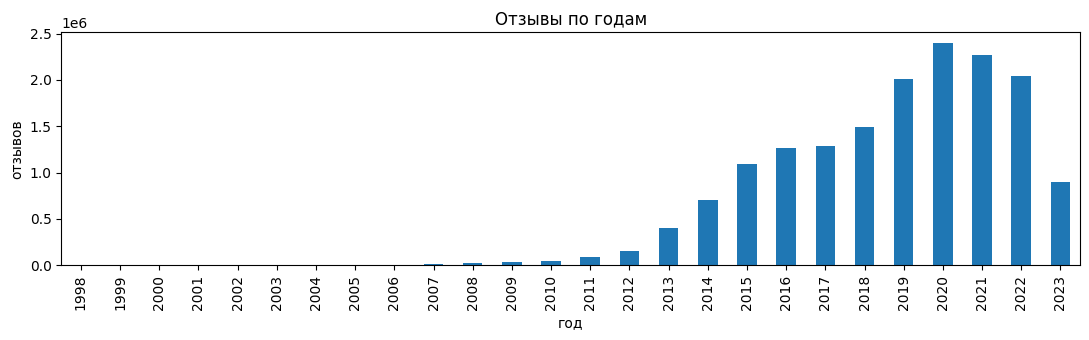


Пар соседних взаимодействий пользователя с одинаковым timestamp: 0.00%
Пользователей (с ≥2 товарами), у кого есть такие пары: 0.01%

Интервал между соседними взаимодействиями пользователя, дни:
count    7936214.00
mean         266.79
std          507.03
min            0.00
10%            0.00
25%            0.00
50%           26.83
75%          313.50
90%          847.01
max         8097.24


In [38]:
dt = pd.to_datetime(rv['timestamp'], unit='ms')
print(f'Диапазон: {dt.min()} — {dt.max()}')

fig, ax = plt.subplots(figsize=(11, 3.5))
dt.dt.year.value_counts().sort_index().plot.bar(ax=ax, color='C0')
ax.set_xlabel('год'); ax.set_ylabel('отзывов'); ax.set_title('Отзывы по годам')
plt.tight_layout(); plt.show()

# Одинаковое время у соседних взаимодействий одного пользователя (после удаления повторов пар)
uu, tt = u[first], ts[first]
order = np.lexsort((tt, uu))
uu, tt = uu[order], tt[order]
same_user = uu[1:] == uu[:-1]
tie = same_user & (tt[1:] == tt[:-1])
users_with_tie = np.unique(uu[1:][tie]).size
users_multi = np.unique(uu[1:][same_user]).size
print(f'\nПар соседних взаимодействий пользователя с одинаковым timestamp: {tie.sum() / same_user.sum():.2%}')
print(f'Пользователей (с ≥2 товарами), у кого есть такие пары: {users_with_tie / max(users_multi, 1):.2%}')

gap_days = (tt[1:] - tt[:-1])[same_user] / 86_400_000
print('\nИнтервал между соседними взаимодействиями пользователя, дни:')
print(pd.Series(gap_days).describe(percentiles=[.1, .25, .5, .75, .9]).round(2).to_string())

### 4.4 Рейтинги и служебные поля

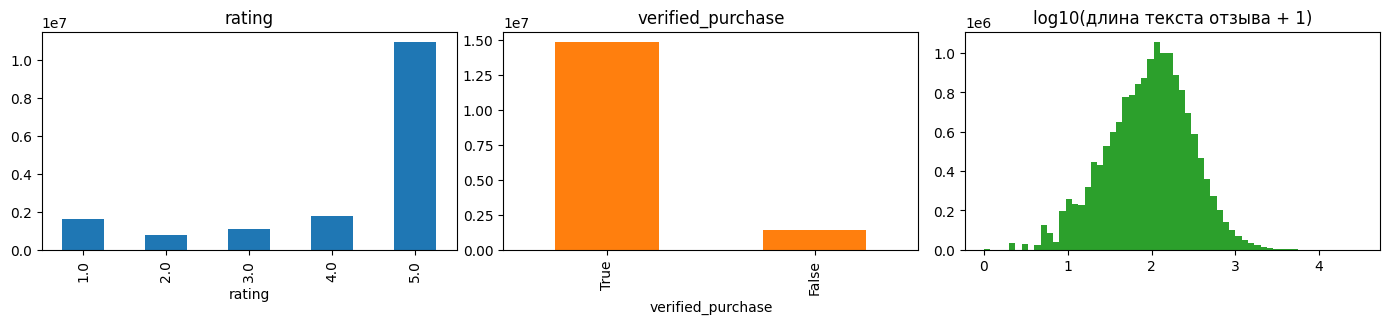

helpful_vote: {'count': 16260406.0, 'mean': 0.83, 'std': 8.45, 'min': -3.0, '50%': 0.0, '90%': 2.0, '99%': 13.0, 'max': 6717.0}
Отзывов с картинками: 6.90%
Пустой текст отзыва:  0.01%


In [39]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
rv['rating'].value_counts().sort_index().plot.bar(ax=axes[0], color='C0', title='rating')
rv['verified_purchase'].value_counts().plot.bar(ax=axes[1], color='C1', title='verified_purchase')
axes[2].hist(np.log10(rv['text_len'] + 1), bins=60, color='C2')
axes[2].set_title('log10(длина текста отзыва + 1)')
plt.tight_layout(); plt.show()

print('helpful_vote:', rv['helpful_vote'].describe(percentiles=[.5, .9, .99]).round(2).to_dict())
print(f'Отзывов с картинками: {(rv["n_images"] > 0).mean():.2%}')
print(f'Пустой текст отзыва:  {(rv["text_len"] == 0).mean():.2%}')

### 4.5 Активность пользователей и товаров

Считаем по уникальным парам (user, parent_asin). Распределения тяжелохвостые, поэтому CCDF в
log-log: доля пользователей (товаров) с ≥ n взаимодействиями.

       на пользователя   на товар
count       8116226.00  890667.00
mean              1.98      18.02
std               3.48      94.29
min               1.00       1.00
50%               1.00       3.00
75%               2.00      10.00
90%               4.00      31.00
99%              12.00     256.00
99.9%            35.00    1142.33
max            2891.00   18484.00


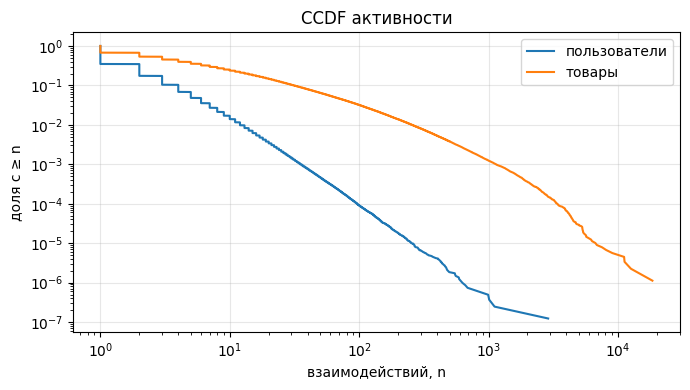

Пользователей с ≥ 1 товарами:  8,116,226 (100.00%)
Пользователей с ≥ 2 товарами:  2,834,076 (34.92%)
Пользователей с ≥ 5 товарами:    555,862 (6.85%)
Пользователей с ≥10 товарами:    138,762 (1.71%)
Пользователей с ≥20 товарами:     30,675 (0.38%)


In [40]:
uq, iq = u[first], i[first]
user_cnt = np.bincount(uq, minlength=rv['user_id'].cat.categories.size)
item_cnt = np.bincount(iq, minlength=rv['parent_asin'].cat.categories.size)
user_cnt, item_cnt = user_cnt[user_cnt > 0], item_cnt[item_cnt > 0]

pct = [.5, .75, .9, .99, .999]
print(pd.DataFrame({'на пользователя': pd.Series(user_cnt).describe(percentiles=pct),
                    'на товар':        pd.Series(item_cnt).describe(percentiles=pct)}).round(2))

fig, ax = plt.subplots(figsize=(7, 4))
for cnt, label in ((user_cnt, 'пользователи'), (item_cnt, 'товары')):
    x = np.sort(cnt)
    ax.loglog(x, 1.0 - np.arange(x.size) / x.size, label=label)
ax.set_xlabel('взаимодействий, n'); ax.set_ylabel('доля с ≥ n'); ax.legend(); ax.grid(alpha=.3)
ax.set_title('CCDF активности')
plt.tight_layout(); plt.show()

for n_min in (1, 2, 5, 10, 20):
    print(f'Пользователей с ≥{n_min:2d} товарами: {(user_cnt >= n_min).sum():>10,} '
          f'({(user_cnt >= n_min).mean():.2%})')

### 4.6 k-core

Итеративный k-core: удаляем пользователей и товары с числом взаимодействий меньше k, пока
ничего не меняется (удаление одних снижает счётчики других). Считаем по уникальным парам
(user, parent_asin).

In [41]:
def k_core(u, i, k_user, k_item, max_iter=200):
    """Маска строк, переживших итеративный k-core, и число итераций."""
    keep = np.ones(u.size, bool)
    n_u, n_i = (u.max() + 1, i.max() + 1) if u.size else (0, 0)
    for it in range(1, max_iter + 1):
        uc = np.bincount(u[keep], minlength=n_u)
        ic = np.bincount(i[keep], minlength=n_i)
        new = keep & (uc[u] >= k_user) & (ic[i] >= k_item)
        if new.sum() == keep.sum():
            return keep, it
        keep = new
    raise RuntimeError('k-core не сошёлся')


def core_stats(u, i, keep, max_len=11):
    """Размеры после фильтра; interactions_trunc — если у пользователя оставить последние max_len
    взаимодействий (как в ATG: история ≤ 10 + таргет)."""
    per_user = np.bincount(u[keep])
    per_user = per_user[per_user > 0]
    n_users = per_user.size
    return {'users': n_users, 'items': np.unique(i[keep]).size, 'interactions': int(keep.sum()),
            'interactions_trunc': int(np.minimum(per_user, max_len).sum()),
            'per_user': keep.sum() / max(n_users, 1)}


rows = []
for k in (2, 3, 5, 10, 20):
    keep, it = k_core(uq, iq, k, k)
    rows.append({'k': k, **core_stats(uq, iq, keep), 'iters': it})
pd.DataFrame(rows).set_index('k').style.format({'users': '{:,}', 'items': '{:,}', 'interactions': '{:,}',
                                                'interactions_trunc': '{:,}', 'per_user': '{:.2f}'})

,users,items,interactions,interactions_trunc,per_user,iters
k,,,,,,
2,"2,761,124","508,741","10,424,686","9,518,852",3.78,9
3,"1,311,215","330,498","7,255,382","6,411,657",5.53,12
5,"432,264","162,035","3,861,886","3,166,983",8.93,16
10,"41,744","31,132","728,215","451,193",17.44,33
20,0,0,0,0,0.00,7


## 5. Метаданные товаров

### 5.1 Идентификаторы и категории

In [53]:
print(f'Записей: {len(meta):,}, уникальных parent_asin: {meta["parent_asin"].nunique():,}, '
      f'без parent_asin: {meta["parent_asin"].isna().sum():,}')
print('\nmain_category (top-15):')
print(meta['main_category'].value_counts(dropna=False).head(15).to_string())

Записей: 890,874, уникальных parent_asin: 890,874, без parent_asin: 0

main_category (top-15):
main_category
Toys & Games                712374
Amazon Home                  45468
AMAZON FASHION               23714
None                         21857
Sports & Outdoors            17541
Office Products              11934
Arts, Crafts & Sewing         9841
Industrial & Scientific       7034
Baby                          6532
All Electronics               6101
Tools & Home Improvement      4890
Automotive                    4737
Health & Personal Care        4022
Camera & Photo                3903
All Beauty                    2221


### 5.2 Заполненность и длины текстовых полей

Текст товара для TEM-энкодера будет собираться из `title`, `features`, `description`,
`categories`, `store` (и, возможно, `details`). Смотрим заполненность по всем товарам и по
товарам, которые переживают 5-core — только они попадут в датасет.

In [54]:
def text_len(v):
    return sum(len(x) for x in v) if isinstance(v, (list, np.ndarray)) else len(v or '')


def nonempty(col):
    s = meta[col]
    if col in ('features', 'description', 'categories'):
        return s.map(len) > 0
    if col in ('details', 'bought_together', 'extra'):
        return s.notna() & ~s.isin(['{}', '[]', 'null'])
    if s.dtype == object:
        return s.notna() & (s.fillna('').str.strip() != '')
    return s.notna()


keep5, _ = k_core(uq, iq, 5, 5)
items5 = set(rv['parent_asin'].cat.categories[np.unique(iq[keep5])])
in5 = meta['parent_asin'].isin(items5)

fill_cols = ['title', 'features', 'description', 'categories', 'store', 'details', 'price',
             'average_rating', 'rating_number', 'bought_together', 'extra']
fill = pd.DataFrame({
    'все товары, %':   {c: 100 * nonempty(c).mean() for c in fill_cols},
    'товары 5-core, %': {c: 100 * nonempty(c)[in5].mean() for c in fill_cols},
}).round(1)
print(f'Товаров в метаданных: {len(meta):,}, из них в 5-core: {in5.sum():,}')
fill

Товаров в метаданных: 890,874, из них в 5-core: 162,035


,"все товары, %","товары 5-core, %"
title,100.0,100.0
features,80.1,94.2
description,65.7,67.5
categories,90.0,96.7
store,99.4,99.9
details,97.7,98.0
price,48.1,64.0
average_rating,100.0,100.0
rating_number,100.0,100.0
bought_together,0.0,0.0


Длины в символах (товары 5-core):
                               count    mean    std  min    10%     50%     90%     99%      max
title                       162035.0   100.0   55.0  0.0   37.0    85.0   187.0   200.0    488.0
features                    162035.0   605.0  526.0  0.0   73.0   430.0  1374.0  2166.0   6363.0
description                 162035.0   437.0  555.0  0.0    0.0   279.0  1078.0  2260.0  14277.0
details                     162035.0   387.0  167.0  2.0  227.0   357.0   593.0   902.0   3724.0
title+features+description  162035.0  1141.0  757.0  0.0  281.0  1040.0  2081.0  3489.0  14681.0

Число элементов в списках (товары 5-core):
                  count  mean  std  min  50%  90%   99%    max
n_features     162035.0   4.5  1.7  0.0  5.0  6.0   9.0   19.0
n_description  162035.0   1.7  4.2  0.0  1.0  4.0  21.0  258.0
n_categories   162035.0   3.5  1.0  0.0  3.0  5.0   5.0    6.0


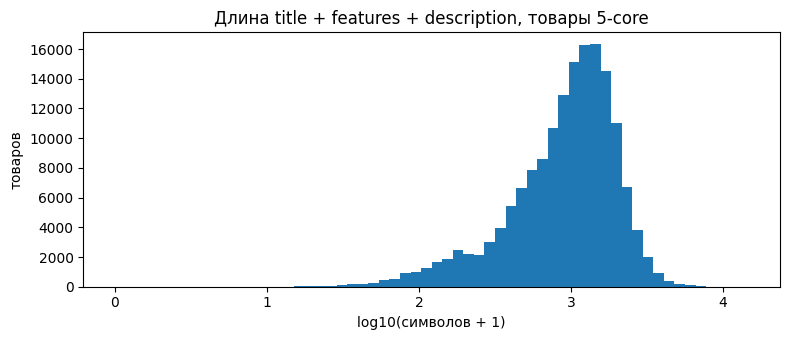

In [55]:
lens = pd.DataFrame({
    'title':       meta['title'].fillna('').str.len(),
    'features':    meta['features'].map(text_len),
    'description': meta['description'].map(text_len),
    'details':     meta['details'].fillna('').str.len(),
})
lens['title+features+description'] = lens[['title', 'features', 'description']].sum(axis=1)
counts = pd.DataFrame({'n_features': meta['features'].map(len),
                       'n_description': meta['description'].map(len),
                       'n_categories': meta['categories'].map(len)})

print('Длины в символах (товары 5-core):')
print(lens[in5].describe(percentiles=[.1, .5, .9, .99]).round(0).T.to_string())
print('\nЧисло элементов в списках (товары 5-core):')
print(counts[in5].describe(percentiles=[.5, .9, .99]).round(1).T.to_string())

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(np.log10(lens.loc[in5, 'title+features+description'] + 1), bins=60)
ax.set_xlabel('log10(символов + 1)'); ax.set_ylabel('товаров')
ax.set_title('Длина title + features + description, товары 5-core')
plt.tight_layout(); plt.show()

### 5.3 Иерархия категорий, бренды, `details`

In [56]:
cats = meta.loc[in5, 'categories']
print('Глубина пути категорий (товары 5-core):')
print(cats.map(len).value_counts().sort_index().to_string())

for level in (0, 1):
    top = cats[cats.map(len) > level].map(lambda c: ' > '.join(c[:level + 1]))
    print(f'\nУровень {level + 1}, top-15 из {top.nunique():,}:')
    print(top.value_counts().head(15).to_string())

store = meta.loc[in5, 'store']
print(f'\nstore: {store.nunique():,} разных у {store.notna().sum():,} товаров; top-10:')
print(store.value_counts().head(10).to_string())

Глубина пути категорий (товары 5-core):
categories
0     5394
2     5742
3    73094
4    49796
5    27967
6       42

Уровень 1, top-15 из 3:
categories
Toys & Games                                154974
Remote & App Controlled Vehicles & Parts      1246
Remote & App Controlled Vehicle Parts          421

Уровень 2, top-15 из 172:
categories
Toys & Games > Preschool                                   39046
Toys & Games > Toy Figures & Playsets                      17789
Toys & Games > Games & Accessories                         15064
Toys & Games > Sports & Outdoor Play                        9611
Toys & Games > Remote & App Controlled Vehicles & Parts     8251
Toys & Games > Arts & Crafts                                7349
Toys & Games > Dolls & Accessories                          7172
Toys & Games > Party Supplies                               6687
Toys & Games > Puzzles                                      6323
Toys & Games > Novelty & Gag Toys                           5779
Toys &

In [57]:
details = meta.loc[in5, 'details'].dropna().map(json.loads)
dk = Counter(k for d in details for k in d)
print(f'details: {len(dk):,} разных ключей у {len(details):,} товаров 5-core; top-30 (доля товаров):')
print(pd.Series({k: c / in5.sum() for k, c in dk.most_common(30)}).map('{:.1%}'.format).to_string())

print('\nprice:', meta.loc[in5, 'price'].describe(percentiles=[.5, .9]).round(2).to_dict())
odd = meta.loc[meta['price'].isna() & meta['price_raw'].notna(), 'price_raw']
print(f'Нечисловых price: {len(odd):,}', odd.value_counts().head(5).to_dict())

details: 1,288 разных ключей у 162,035 товаров 5-core; top-30 (доля товаров):
Manufacturer                         93.1%
Item Weight                          92.3%
Best Sellers Rank                    79.8%
Product Dimensions                   78.7%
Manufacturer recommended age         77.3%
Item model number                    70.5%
Is Discontinued By Manufacturer      57.3%
Brand                                37.5%
Release date                         32.5%
Material                             21.8%
Color                                18.7%
Country of Origin                    18.5%
Theme                                17.3%
Age Range (Description)              15.0%
Package Dimensions                   14.3%
Date First Available                 13.9%
Item Dimensions LxWxH                12.5%
Department                           11.2%
Number of Pieces                     10.8%
Batteries                            10.1%
Style                                 7.5%
Size               

In [58]:
# Несколько случайных товаров из 5-core целиком
for _, row in meta[in5].sample(3, random_state=SEED).iterrows():
    print('=' * 100)
    for col in ('parent_asin', 'main_category', 'title', 'store', 'categories', 'features',
                'description', 'details', 'price', 'average_rating', 'rating_number'):
        print(f'{col:15s} {short(row[col].tolist() if isinstance(row[col], np.ndarray) else row[col], 400)}')

parent_asin     'B09P4FNWBB'
main_category   'Toys & Games'
title           'Disney Mickey Mouse, 2-Puzzle Pack 36-Piece Jigsaw Puzzles Storage Tubes Disney Toys Mickey Mouse Clubhouse Kids Puzzles Disney Gifts, for Ages 4 and up'
store           'Spin Master Games'
categories      list[3] ["'Toys & Games'", "'Games & Accessories'", "'Board Games'"]
features        list[7] ["'2 PUZZLE TUBES: Get a great value with these 36-piece kids ...", "'VIBRANT IMAGES: Have fun with Mickey, Pluto, Goofy, and Don...", "'YOUR FAVORITE CLASSIC DISNEY SHOW: Both you and the kids wi..."] ...
description     list[1] ["'From Disney Junior’s Mickey show, these children’s jigsaw p..."]
details         '{"Product Dimensions": "8.13 x 3 x 10 inches", "Item Weight": "13.4 ounces", "Country of Origin": "China", "Item model number": "6065796", "Manufacturer recommended age": "4 years and up", "Best Sellers Rank": {"Toys & Games": 104041, "Board Games": 3437, "Pre-Kindergarten Toys": 42432}, "Release date": "Jun

### 5.4 Покрытие: отзывы ↔ метаданные

In [59]:
meta_ids = set(meta['parent_asin'].dropna())
rev_ids  = set(rv['parent_asin'].cat.categories)
titled   = set(meta.loc[nonempty('title'), 'parent_asin'])

print(f'Товаров в отзывах:                  {len(rev_ids):>10,}')
print(f'  из них есть в метаданных:         {len(rev_ids & meta_ids):>10,}')
print(f'  есть непустой title:              {len(rev_ids & titled):>10,}')
print(f'Товаров в метаданных без отзывов:   {len(meta_ids - rev_ids):>10,}')
no_meta = ~rv['parent_asin'].isin(meta_ids)
print(f'Отзывов на товары без метаданных:   {no_meta.sum():>10,} ({no_meta.mean():.2%})')
print(f'Товаров 5-core без метаданных:      {len(items5 - meta_ids):>10,} из {len(items5):,}')

Товаров в отзывах:                     890,667
  из них есть в метаданных:            890,667
  есть непустой title:                 890,630
Товаров в метаданных без отзывов:          207
Отзывов на товары без метаданных:            0 (0.00%)
Товаров 5-core без метаданных:               0 из 162,035


### 5.5 Текстовое описание товаров предобработанного датасета

Для товаров из `data/processed/toys/interactions.parquet` (результат `scripts/preprocess.py`)
собираем текст по шаблону:

```
title: <title>
store_title: <store>
features: <пункты features через " | ">
categories: <путь категорий через " > ">
```

Сборка и чистка текста — в `src/item_text.py`: тот же код пишет `data/processed/toys/items.parquet`
в `scripts/preprocess.py`, так что ноутбук и скрипт не расходятся. Здесь параметры можно менять и
смотреть, что получается.

Результат — таблица `items_text`, отсортированная по убыванию числа взаимодействий (позиция 0 —
самый популярный товар):

* `text_raw` — поля как есть, только схлопнуты пробельные символы;
* `text` — после чистки по правилам (ниже).

Посмотреть товар: `show(позиция)` или `show('parent_asin')`.

In [64]:
import sys
sys.path.insert(0, str(Path('../src').resolve()))
from item_text import TextConfig, build_item_texts, clean, clean_features, clean_list, popularity

PREP_PATH = Path('../data/processed/toys/interactions.parquet')   # результат scripts/preprocess.py

item_pop = popularity(pd.read_parquet(PREP_PATH, columns=['parent_asin'])['parent_asin'])
m = meta.set_index('parent_asin').reindex(item_pop.index)
print(f'{PREP_PATH}: {item_pop.sum():,} взаимодействий, {item_pop.size:,} товаров; '
      f'без метаданных: {(~item_pop.index.isin(meta["parent_asin"])).sum():,}')

..\data\processed\toys\interactions.parquet: 2,874,709 взаимодействий, 273,131 товаров; без метаданных: 0


**Чистка по правилам** (`TextConfig` в `src/item_text.py`). Детерминированная и воспроизводимая,
ничего не дописывает — только убирает шум, из-за которого эмбеддинг длинного текста уходит в
маркетинг, а не в смысл товара:

* `max_features`, `max_features_chars` — из `features` берутся первые пункты целиком, пока не
  превышен лимит пунктов или символов; если длиннее лимита уже первый пункт, он обрезается по
  границе слова. Повторяющиеся пункты убираются;
* `strip_symbols` — эмодзи и знаки ™ ® © (во всех полях);
* `strip_prefixes` — служебные префиксы в начале пункта: «Features:», «Product Description -» и т. п.;
* `fix_caps_headers` — заголовок пункта капслоком → обычный регистр: «CHILD SAFETY - Meet…» →
  «Child safety: Meet…». По умолчанию выключено: эмбеддингу регистр почти безразличен, а бренды
  внутри заголовка теряют написание («lego»).

Title, store и categories не обрезаются: в них и сосредоточен смысл товара.

In [65]:
# Как TEXT в scripts/preprocess.py (items.parquet); здесь можно пробовать другие значения
TEXT_CFG = TextConfig(
    feature_sep=' | ',
    max_features=5,
    max_features_chars=800,
    strip_symbols=True,
    strip_prefixes=True,
    fix_caps_headers=False,
)

items_text = build_item_texts(m.reset_index(), TEXT_CFG)
items_text.insert(1, 'n_interactions', item_pop.to_numpy())
print(f'Текст изменился у {(items_text["text"] != items_text["text_raw"]).mean():.1%} товаров')
items_text.head(10)

Текст изменился у 36.6% товаров


,parent_asin,n_interactions,text,text_raw
0,B0BW3QTWJJ,2789,"title: Baby Einstein Baby's First Music Teacher Developmental Toys Kit and Gift Set, Newborn and up\nstore_title: Ba...","title: Baby Einstein Baby's First Music Teacher Developmental Toys Kit and Gift Set, Newborn and up\nstore_title: Ba..."
1,B0054TRQA4,2689,"title: Aurora World Flopsie Drake Dolphin 12""\nstore_title: Aurora Plush\nfeatures: 12 inches in size.\ncategories: ...","title: Aurora World Flopsie Drake Dolphin 12""\nstore_title: Aurora Plush\nfeatures: 12 inches in size.\ncategories: ..."
2,B07N29HQMN,2288,"title: Aurora - Mini Flopsie - 8"" Caramel Horse\nstore_title: Aurora World\nfeatures: 8 inches in size. | High quali...","title: Aurora - Mini Flopsie - 8"" Caramel Horse\nstore_title: Aurora World\nfeatures: 8 inches in size. | High quali..."
3,B07C4NGT17,1883,title: The First Years Stack N Count Cups\nstore_title: The First Years\nfeatures: Colorful Baby Toys: 8 brightly co...,title: The First Years Stack N Count Cups\nstore_title: The First Years\nfeatures: Colorful Baby Toys: 8 brightly co...
4,B004S8F7QM,1845,title: Cards Against Humanity\nstore_title: Cards Against Humanity LLC.\nfeatures: A party game for horrible people....,title: Cards Against Humanity\nstore_title: Cards Against Humanity LLC.\nfeatures: A party game for horrible people....
5,B0C3H818H4,1831,"title: Exploding Kittens Party Pack Card Game by Exploding kittens - A Russian Roulette Fun Family Games for Adults,...","title: Exploding Kittens Party Pack Card Game by Exploding kittens - A Russian Roulette Fun Family Games for Adults,..."
6,B00D8STBHY,1511,"title: Hasbro Gaming Connect 4 Classic Grid,4 in a Row Game,Strategy Board Games for Kids,2 Player .for Family and K...","title: Hasbro Gaming Connect 4 Classic Grid,4 in a Row Game,Strategy Board Games for Kids,2 Player .for Family and K..."
7,B09QPXVW35,1343,"title: Jenga Classic Game with Genuine Hardwood Blocks, Stacking Tower Game for 1 or More Players, Kids Ages 6 and U...","title: Jenga Classic Game with Genuine Hardwood Blocks, Stacking Tower Game for 1 or More Players, Kids Ages 6 and U..."
8,B0BDXWGW31,1341,title: Click N' Play Phthalate Free BPA Free Crush Proof Plastic Ball Pit Balls in Reusable and Durable Storage Mesh...,title: Click N' Play Phthalate Free BPA Free Crush Proof Plastic Ball Pit Balls in Reusable and Durable Storage Mesh...
9,B0BZJFF2BF,1224,title: Stomp Rocket The Original Ultra Rocket Launcher (LED - 6 Rockets)\nstore_title: Stomp Rocket\nfeatures: 100% ...,title: Stomp Rocket The Original Ultra Rocket Launcher (LED - 6 Rockets)\nstore_title: Stomp Rocket\nfeatures: 100% ...


Доля товаров с непустым полем:
title          100.0%
store_title     99.8%
features        90.7%
categories      94.9%
Пустой текст целиком: 1
features обрезаны (стало меньше пунктов) у 35.2% товаров

Длина текста, символов (≈ токенов × 4):
             count   mean    std  min    10%    50%     90%     99%     max
text_raw  273131.0  792.0  570.0  0.0  222.0  593.0  1638.0  2439.0  6442.0
text      273131.0  604.0  298.0  0.0  221.0  569.0  1005.0  1102.0  1333.0


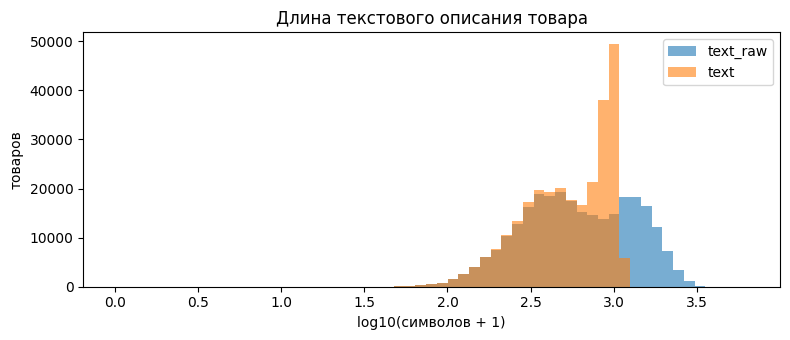

In [66]:
# Какие поля попали в текст и какой он длины
text_fill = pd.Series({
    'title':       m['title'].map(clean).astype(bool).mean(),
    'store_title': m['store'].map(clean).astype(bool).mean(),
    'features':    m['features'].map(lambda v: bool(clean_list(v))).mean(),
    'categories':  m['categories'].map(lambda v: bool(clean_list(v))).mean(),
})
print('Доля товаров с непустым полем:')
print(text_fill.map('{:.1%}'.format).to_string())
print(f'Пустой текст целиком: {(items_text["text"] == "").sum():,}')

n_feat_raw   = m['features'].map(lambda v: len(clean_list(v)))
n_feat_clean = m['features'].map(lambda v: len(clean_features(v, TEXT_CFG)))
print(f'features обрезаны (стало меньше пунктов) у {(n_feat_clean < n_feat_raw).mean():.1%} товаров')

text_chars = pd.DataFrame({'text_raw': items_text['text_raw'].str.len(),
                           'text':     items_text['text'].str.len()})
print('\nДлина текста, символов (≈ токенов × 4):')
print(text_chars.describe(percentiles=[.1, .5, .9, .99]).round(0).T.to_string())

fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(0, np.log10(text_chars.to_numpy().max() + 1), 60)
for col in ('text_raw', 'text'):
    ax.hist(np.log10(text_chars[col] + 1), bins=bins, alpha=.6, label=col)
ax.set_xlabel('log10(символов + 1)'); ax.set_ylabel('товаров'); ax.legend()
ax.set_title('Длина текстового описания товара')
plt.tight_layout(); plt.show()

In [67]:
_position = pd.Series(items_text.index, index=items_text['parent_asin'])


def show(key, raw=True):
    """Печатает текст товара: key — позиция в items_text (int) или parent_asin (str);
    raw=True — ещё и text_raw для сравнения, если чистка его изменила."""
    pos = _position[key] if isinstance(key, str) else int(key)
    row = items_text.iloc[pos]
    print(f'[{pos}] {row["parent_asin"]} — взаимодействий: {row["n_interactions"]}')
    print(row['text'] or '<пустой текст>')
    if raw and row['text_raw'] != row['text']:
        print('--- text_raw ---')
        print(row['text_raw'])
    print()


show(0)                           # самый популярный товар
show(len(items_text) // 2)        # из середины
show(len(items_text) - 1)         # из самых редких
for pos in np.random.default_rng(SEED).choice(len(items_text), 3, replace=False):
    show(pos)

[0] B0BW3QTWJJ — взаимодействий: 2789
title: Baby Einstein Baby's First Music Teacher Developmental Toys Kit and Gift Set, Newborn and up
store_title: Baby Einstein
features: Extraordinary value and variety inside this boxed play set that helps expose your little one to music with an award-winning developmental Baby Einstein item, plus other best sellers | Includes 8 items: 4 baby musical toys; a board book; downloadable DIY activities; details for streaming Baby Einstein music on Spotify and edutainment videos on YouTube; and exclusive offers for Kinedu and Good Buy Gear | Discover & Play Piano Baby Toy Piano; Take Along Tunes Musical Toy; Rattle & Jingle Trio Take-Along Toy Rattle Set; Ocean Glow Sensory Shaker Musical Toy; and Music Under the Sea Board Book | 40 plus sounds and melodies provide a thorough introduction to classical music and instruments, while aiding in auditory development through sound recognition
categories: Toys & Games > Preschool > Pre-Kindergarten Toys > Music

## 6. Сверка с готовым ATG

Маппинга «индекс ATG → ASIN» нет, поэтому сравнить можно только агрегаты и косвенные признаки
предобработки:

* сплиты — по пользователям или по времени внутри пользователя;
* минимальная и максимальная длина истории, обрезка до 10;
* как пронумерованы товары (растут ли id вдоль последовательности);
* какой фильтр (k-core, окно по времени) даёт похожие размеры.

In [21]:
atg = {s: pd.read_pickle(ATG_DIR / f'{s}_data.df') for s in ('train', 'val', 'test')}
stat = pd.read_pickle(ATG_DIR / 'data_statis.df')
PAD = int(stat['item_num'].iloc[0])
print(stat.to_string(index=False), '\n')

rows = []
for s, d in atg.items():
    full = [[x for x in seq if x != PAD] + [nxt] for seq, nxt in zip(d['seq'], d['next'])]
    rows.append({
        'split': s, 'sequences': len(d),
        'len_seq min': d['len_seq'].min(), 'len_seq max': d['len_seq'].max(),
        'len_seq=10, %': 100 * (d['len_seq'] == 10).mean(),
        'id не убывают, %': 100 * np.mean([all(a <= b for a, b in zip(f, f[1:])) for f in full]),
        'next > max(history), %': 100 * np.mean([f[-1] > max(f[:-1]) for f in full]),
        'mean next id': d['next'].mean(),
    })
atg_summary = pd.DataFrame(rows).set_index('split')
n_seq = atg_summary['sequences'].sum()
print(f'Последовательностей всего: {n_seq:,}; доли сплитов: '
      + ', '.join(f'{s} {v / n_seq:.1%}' for s, v in atg_summary['sequences'].items()))
atg_summary.round(1)

 seq_size  item_num
       10     11924 

Последовательностей всего: 19,412; доли сплитов: train 80.0%, val 10.0%, test 10.0%


,sequences,len_seq min,len_seq max,"len_seq=10, %","id не убывают, %","next > max(history), %",mean next id
split,,,,,,,
train,15529,4,10,17.4,5.7,47.3,7509.7
val,1941,4,10,17.8,5.0,47.4,7398.5
test,1942,4,10,17.4,5.0,45.6,7436.5


In [22]:
atg_items = set()
atg_inter = 0
for d in atg.values():
    for seq, nxt in zip(d['seq'], d['next']):
        real = [x for x in seq if x != PAD]
        atg_items.update(real + [nxt])
        atg_inter += len(real) + 1
print(f'Товаров, встречающихся в сплитах: {len(atg_items):,} из {PAD:,}')
print(f'Взаимодействий в сплитах (история ≤10 + таргет): {atg_inter:,}; '
      f'в AlphaFuse, Table 1 — {ATG_PAPER["interactions"]:,}')
print('Если числа совпадают, статья считает взаимодействия уже после обрезки истории до 10, '
      'и при подборе фильтра ниже сравнивать надо с обрезанными последовательностями.')

Товаров, встречающихся в сплитах: 11,921 из 11,924
Взаимодействий в сплитах (история ≤10 + таргет): 138,444; в AlphaFuse, Table 1 — 138,444
Если числа совпадают, статья считает взаимодействия уже после обрезки истории до 10, и при подборе фильтра ниже сравнивать надо с обрезанными последовательностями.


Поиск фильтра, дающего размеры ATG: k-core при разных k и окнах по времени (взаимодействия с
начала года `from_year`). Смотрим относительное отклонение от чисел из статьи; взаимодействия
сравниваем в обрезанном виде (`interactions_trunc`: не больше 11 на пользователя). В ATG
`len_seq ≥ 4`, то есть у каждого пользователя ≥ 5 взаимодействий, поэтому k начинается с 5.

In [23]:
years = pd.to_datetime(ts[first], unit='ms').year.to_numpy()
rows = []
for from_year in (None, 2014, 2016, 2018, 2019, 2020, 2021, 2022):
    sel = np.ones(uq.size, bool) if from_year is None else years >= from_year
    for k in (5, 10):
        keep, _ = k_core(uq[sel], iq[sel], k, k)
        st = core_stats(uq[sel], iq[sel], keep)
        rows.append({'from_year': from_year or 'все', 'k': k, **st,
                     'Δusers, %': 100 * (st['users'] / ATG_PAPER['users'] - 1),
                     'Δitems, %': 100 * (st['items'] / ATG_PAPER['items'] - 1),
                     'Δinteractions, %': 100 * (st['interactions_trunc'] / ATG_PAPER['interactions'] - 1)})
scan = pd.DataFrame(rows)
scan['max |Δ|, %'] = scan[['Δusers, %', 'Δitems, %', 'Δinteractions, %']].abs().max(axis=1)
scan.sort_values('max |Δ|, %').round(1).head(10)

,from_year,k,users,items,interactions,interactions_trunc,per_user,"Δusers, %","Δitems, %","Δinteractions, %","max |Δ|, %"
14,2022,5,15527,17734,236547,131199,15.2,-20.0,48.7,-5.2,48.7
5,2016,10,18557,18374,351540,200622,18.9,-4.4,54.1,44.9,54.1
7,2018,10,5756,9497,145341,62799,25.3,-70.3,-20.4,-54.6,70.3
9,2019,10,5557,8988,138041,60639,24.8,-71.4,-24.6,-56.2,71.4
11,2020,10,4990,7595,118283,54438,23.7,-74.3,-36.3,-60.7,74.3
13,2021,10,4861,7279,113845,53030,23.4,-75.0,-39.0,-61.7,75.0
15,2022,10,4770,7092,110947,52042,23.3,-75.4,-40.5,-62.4,75.4
3,2014,10,36231,28330,634901,391599,17.5,86.6,137.6,182.9,182.9
12,2021,5,42686,34275,452611,316704,10.6,119.9,187.4,128.8,187.4
1,все,10,41744,31132,728215,451193,17.4,115.0,161.1,225.9,225.9


## 7. Что проверить по итогам прогона

Ответы на эти вопросы определяют пайплайн собственной предобработки:

1. **Единица товара:** `parent_asin` или `asin`; сколько вариаций теряется при переходе к `parent_asin`.
2. **Повторы и одинаковые timestamp:** как дедуплицировать и как упорядочивать ничьи.
3. **Фильтр:** какой k-core / окно по времени; воспроизводит ли что-то размеры ATG или его
   предобработка была иной (например, другой версией датасета).
4. **Сплит:** ATG делит по пользователям (одна последовательность на пользователя, cold-start
   80/10/10) — повторяем так же или берём leave-one-out.
5. **Текст товара:** какие поля входят; как быть с товарами без `title` / метаданных.